<a href="https://colab.research.google.com/github/asrigrisha-2006/ML_AP24110011682/blob/main/Week9(_PCA)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [2]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data?
Yes, approximately equal.

In [3]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [4]:
# Q1: your code here
corr = np.corrcoef(X.T)
print("Correlation Matrix:\n", corr)

features = iris.feature_names
max_corr = -1
min_corr = 1
max_pair = None
min_pair = None

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        if corr[i, j] > max_corr:
            max_corr = corr[i, j]
            max_pair = (features[i], features[j])
        if corr[i, j] < min_corr:
            min_corr = corr[i, j]
            min_pair = (features[i], features[j])

print("\nMost strongly correlated pair:", max_pair, "Correlation:", max_corr)
print("Least correlated pair:", min_pair, "Correlation:", min_corr)

Correlation Matrix:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]

Most strongly correlated pair: ('petal length (cm)', 'petal width (cm)') Correlation: 0.9628654314027958
Least correlated pair: ('sepal width (cm)', 'petal length (cm)') Correlation: -0.42844010433054014


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [5]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Show the characteristic equation is $(1-\lambda)^2-r^2=0$, so $\lambda=1\pm r$.
2. Using the value of $r$ printed above, write both eigenvalues. (Hint: r is negative.)
3. Explained variance of PC1 = $\lambda_1/(\lambda_1+\lambda_2)$ = ___ %
4. Eigenvector for the larger eigenvalue (roughly ±0.71, ∓0.71 pattern): ___


In [6]:
# Use your hand answers to fill in, then verify with np.linalg.eigh(C)
r = C[0, 1]

lambda1 = 1 - r
lambda2 = 1 + r

print("Correlation r:", r)
print("Hand-calculated eigenvalues:", lambda1, lambda2)

explained_variance = lambda2 / (lambda1 + lambda2) * 100
print("Explained variance of PC1:", explained_variance, "%")

eigenvalues, eigenvectors = np.linalg.eigh(C)

print("\nNumPy eigenvalues:", eigenvalues)
print("NumPy eigenvectors:\n", eigenvectors)
print("Eigenvector for the larger eigenvalue:", eigenvectors[:, 1])

Correlation r: -0.6130060338328881
Hand-calculated eigenvalues: 1.613006033832888 0.3869939661671119
Explained variance of PC1: 19.349698308355595 %

NumPy eigenvalues: [0.387 1.613]
NumPy eigenvectors:
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]
Eigenvector for the larger eigenvalue: [-0.7071  0.7071]


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? ___. Run `Z[:, 0]` after finishing the verification to see them.
1 number describes each student because projecting onto PC1 reduces the original 2 features to a single principal component.

## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [7]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / >95%. Then scale and compare below. **Deliberate error:** the unscaled result is misleading. Explain why in one line.

WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


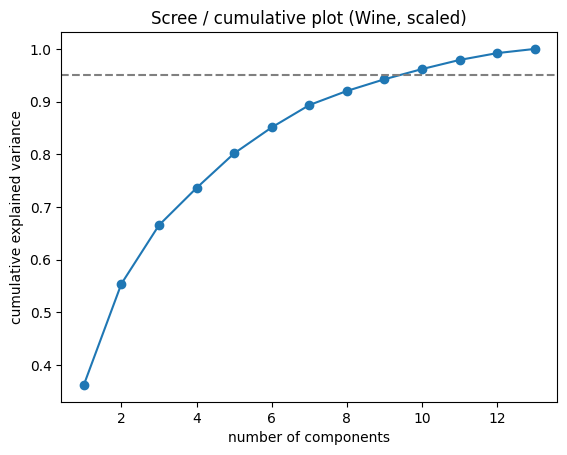

In [8]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

In [9]:
# your code here
wine = load_wine()
X = wine.data

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print("Cumulative explained variance:")
print(cumulative_variance)

n_components = np.argmax(cumulative_variance >= 0.95) + 1
print("\nComponents needed for 95% variance:", n_components)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

Cumulative explained variance:
[0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]

Components needed for 95% variance: 10

Explained variance ratio:
[0.362  0.1921 0.1112 0.0707 0.0656 0.0494 0.0424 0.0268 0.0222 0.0193
 0.0174 0.013  0.008 ]


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [10]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / ~30 / ~55. And what will KNN accuracy look like with only 10 components?
1. Guess for 90% variance: ~15 components.

2. KNN accuracy with only 10 components: It will likely remain reasonably high because PCA preserves most of the important information, but accuracy may decrease slightly compared with using all features. The actual accuracy depends on the train-test split and KNN settings.

### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

In [19]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data
y = digits.target

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)

print("Training data:", Xtr.shape)
print("Testing data:", Xte.shape)

Training data: (1257, 64)
Testing data: (540, 64)


In [21]:
from sklearn.metrics import accuracy_score

In [22]:
# Q1-Q3: your code here
k_values = [2, 5, 10, 20, 30, 40, 64]
baseline = 0.9796

print("k\tKNN Accuracy\tTree Accuracy")

for k in k_values:
    pca = PCA(n_components=k, random_state=1)

    Xtr_pca = pca.fit_transform(Xtr)
    Xte_pca = pca.transform(Xte)

    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(Xtr_pca, ytr)
    knn_acc = accuracy_score(yte, knn.predict(Xte_pca))

    tree = DecisionTreeClassifier(criterion="entropy", random_state=1)
    tree.fit(Xtr_pca, ytr)
    tree_acc = accuracy_score(yte, tree.predict(Xte_pca))

    print(f"{k}\t{knn_acc:.4f}\t\t{tree_acc:.4f}")

    if abs(knn_acc - baseline) <= 0.005:
        print(f"  KNN is within 0.5 percentage points of baseline at k={k}")

k	KNN Accuracy	Tree Accuracy
2	0.6074		0.5593
5	0.9148		0.8611
10	0.9778		0.8481
  KNN is within 0.5 percentage points of baseline at k=10
20	0.9815		0.8463
  KNN is within 0.5 percentage points of baseline at k=20
30	0.9833		0.8370
  KNN is within 0.5 percentage points of baseline at k=30
40	0.9833		0.8370
  KNN is within 0.5 percentage points of baseline at k=40
64	0.9833		0.8481
  KNN is within 0.5 percentage points of baseline at k=64


### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

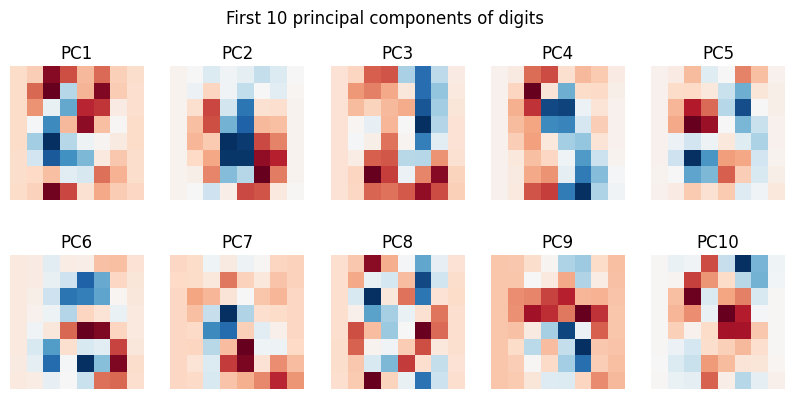

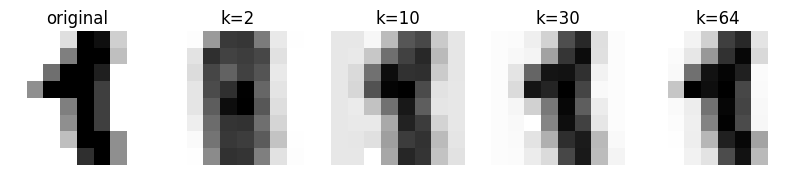

In [23]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

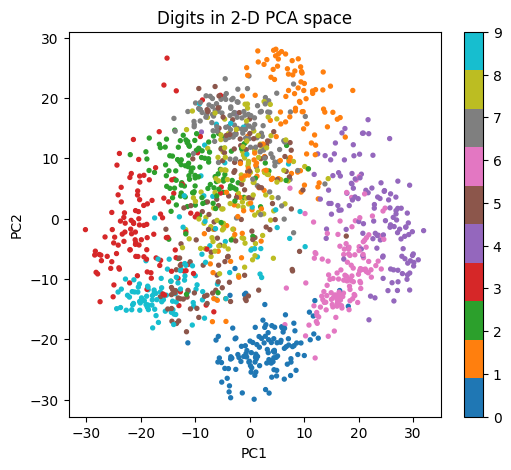

In [15]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?
his is wrong because it causes data leakage. StandardScaler and PCA are fitted on the entire dataset, including the test data, so information from the test set influences the preprocessing

In [16]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [17]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns. (a) What is the maximum number of non-zero principal components? (b) Will 2 components capture >90% of variance?
(a) 5 components maximum.
(b) Not sure; it depends on how much variance the first two components explain.

### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

Explained variance ratio: [0.2642 0.2088]
Sum of explained variance: 0.4730751133209796


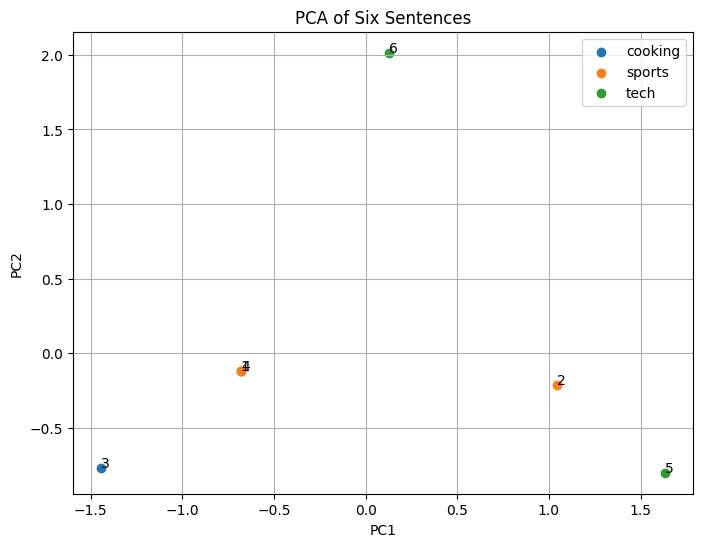


Closest sentence pair: (np.float64(3.767020629521372e-14), 1, 4)

Top 5 words for PC1:
Word_0 0.39455998526351116
Word_3 -0.31333071498175674
Word_26 -0.3133307149817565
Word_21 0.2404983160745603
Word_17 0.2404983160745603

Top 5 words for PC2:
Word_2 0.37580252800626784
Word_14 0.3758025280062677
Word_11 0.3758025280062677
Word_15 0.3758025280062677
Word_5 0.3758025280062677


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from itertools import combinations

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_text)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Sum of explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))

for label in np.unique(labels):
    idx = np.array(labels) == label
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=label)

for i in range(len(X_pca)):
    plt.annotate(str(i + 1), (X_pca[i, 0], X_pca[i, 1]))

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Six Sentences")
plt.legend()
plt.grid(True)
plt.show()

distances = []

for i, j in combinations(range(len(X_pca)), 2):
    distance = np.linalg.norm(X_pca[i] - X_pca[j])
    distances.append((distance, i + 1, j + 1))

print("\nClosest sentence pair:", min(distances))

if "feature_names" in globals():
    words_list = feature_names
elif "vocabulary" in globals():
    words_list = vocabulary
else:
    words_list = [f"Word_{i}" for i in range(X_text.shape[1])]

for pc in range(2):
    top = np.argsort(np.abs(pca.components_[pc]))[::-1][:5]
    print(f"\nTop 5 words for PC{pc + 1}:")
    for i in top:
        print(words_list[i], pca.components_[pc, i])

## Part 6: Reflection (write 2–3 lines each)
1. In your own words: what does PCA keep and what does it throw away?
2. Why must we standardize before PCA? Give the Wine evidence.
3. Digits: pick the k you would deploy and justify (accuracy vs. size).
4. PCA helped KNN but not the tree. What does this say about when to use PCA?
5. PCA is **unsupervised**; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)
6. **Capstone link (Milestone, Week 9):** will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.

*Submit this notebook to GitHub under `labs/week9_pca/`.*